# Task 1 - HAB prediction: preprocessing and model training

This notebook prepares the data in five steps, in this order, and then trains and evaluates models:

1. Split the data 80/20 into train and test sets.
2. Fill the missing `CHL` and `CHL_uncertainty` values with medians computed on the train set only.
3. Apply a log10 transform to `CHL`, which has a long right tail.
4. Z-score normalize the continuous features with means and standard deviations computed on the train set only.
5. Oversample `HAB = 1` in the train set with SMOTE, so the classes are balanced. The test set isn't resampled.

Models are trained on the SMOTE train set and evaluated on the real test set. A baseline that predicts the historical
HAB rate of each season and spatial cluster shows how much the models add, and chronological 5-fold cross-validation on
the train set gives the scores for comparing models, so the test set isn't used to choose between them.

Computing these values after the split, from the train set alone, stops information from the test set leaking into training.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPClassifier

DATA_PATH = Path("classification_task1_train.csv")
TARGET = "HAB"
IMPUTE_COLUMNS = ["CHL", "CHL_uncertainty"]
LOG_COLUMN = "CHL"
SCALE_COLUMNS = ["CHL", "CHL_uncertainty", "SST", "UI", "YDOY"]
TRAIN_SHARE = 0.8
CATEGORY_COLUMNS = ["Season", "spatial_cluster"]
SMOTE_NEIGHBOURS = 5
SMOTE_SEED = 0
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]
CLUSTERS = [0, 1, 2, 3, 4, 5]

LINE_COLOR = "#2a78d6"
GRID_COLOR = "#e4e3df"

## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", parse_dates=["Date"])
df = df.sort_values("Date", kind="stable").reset_index(drop=True)

print(f"{df.shape[0]} rows, {df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d}")
df.isna().sum().to_frame("missing values")

1063 rows, 2013-02-19 to 2020-12-29


,missing values
Date,0
Day,0
Month,0
Year,0
Season,0
CHL,500
CHL_uncertainty,500
SST,0
UI,0
YDOY,0


## 2. Chronological 80/20 split

The split is chronological because the manual asks for a chronological validation split and the model will be evaluated on
later years (2021-2023). The earliest rows form the train set and the latest rows form the test set.

Some dates have several rows, one for each spatial cluster sampled that day. The cut is placed on a date boundary so that a
date never appears in both sets, which makes the split close to 80/20 rather than exact.

In [3]:
cutoff_date = df["Date"].iloc[int(len(df) * TRAIN_SHARE)]
train = df[df["Date"] < cutoff_date]
test = df[df["Date"] >= cutoff_date]


def split_summary(data):
    """Return the size, date range, HAB rate and missing CHL share of a split."""
    return {
        "rows": len(data),
        "share (%)": round(len(data) / len(df) * 100, 1),
        "first date": f"{data['Date'].min():%Y-%m-%d}",
        "last date": f"{data['Date'].max():%Y-%m-%d}",
        "positives": data[TARGET].sum(),
        "HAB rate (%)": round(data[TARGET].mean() * 100, 1),
        "missing CHL (%)": round(data["CHL"].isna().mean() * 100, 1),
    }


pd.DataFrame({"Train": split_summary(train), "Test": split_summary(test)}).T

,rows,share (%),first date,last date,positives,HAB rate (%),missing CHL (%)
Train,850,80.0,2013-02-19,2019-08-19,98,11.5,46.8
Test,213,20.0,2019-08-21,2020-12-29,40,18.8,47.9


## 3. Median imputation

The medians come from the train set only, and the same values fill the gaps in both sets. This uses plain pandas because the
manual doesn't allow library imputers in the submission.

In [4]:
train_medians = train[IMPUTE_COLUMNS].median()

train_imputed = train.fillna(train_medians)
test_imputed = test.fillna(train_medians)

pd.DataFrame({
    "train median (used to fill)": train_medians,
    "test median (not used)": test[IMPUTE_COLUMNS].median(),
    "filled in train": train[IMPUTE_COLUMNS].isna().sum(),
    "filled in test": test[IMPUTE_COLUMNS].isna().sum(),
}).round(2)

,train median (used to fill),test median (not used),filled in train,filled in test
CHL,2.89,2.98,398,102
CHL_uncertainty,32.45,34.25,398,102


## 4. Check the result

Each check stops the notebook with an error if it fails.

In [5]:
for name, original, imputed in [("Train", train, train_imputed), ("Test", test, test_imputed)]:
    assert imputed.notna().all().all(), f"{name}: missing values remain"
    assert len(imputed) == len(original), f"{name}: row count changed"
    for column in IMPUTE_COLUMNS:
        was_missing = original[column].isna()
        assert (imputed.loc[was_missing, column] == train_medians[column]).all(), f"{name}: wrong fill for {column}"
        assert imputed.loc[~was_missing, column].equals(original.loc[~was_missing, column]), f"{name}: {column} changed"

assert len(train) + len(test) == len(df), "Rows were lost in the split"
assert train["Date"].max() < test["Date"].min(), "Train and test overlap in time"

print("All checks passed")

All checks passed


## 5. Log transform of CHL

`CHL` becomes `log10(CHL)` in both sets, after imputation and before scaling, so filled rows get the log of the train median.
The transform has no fitted values, so it can't leak information between the sets. It needs every value to be positive,
which the first check below confirms. `CHL_uncertainty` isn't transformed.

In [6]:
def log_chl(data):
    """Return a copy of the data with LOG_COLUMN replaced by its log10."""
    assert (data[LOG_COLUMN] > 0).all(), "log10 needs positive values"
    logged = data.copy()
    logged[LOG_COLUMN] = np.log10(data[LOG_COLUMN])
    return logged


train_logged = log_chl(train_imputed)
test_logged = log_chl(test_imputed)

for imputed, logged in [(train_imputed, train_logged), (test_imputed, test_logged)]:
    assert ((10 ** logged[LOG_COLUMN] - imputed[LOG_COLUMN]).abs() < 1e-9).all(), "log10 can't be reversed"
    assert logged.drop(columns=LOG_COLUMN).equals(imputed.drop(columns=LOG_COLUMN)), "Another column changed"

pd.DataFrame({
    "skewness before log": [train_imputed[LOG_COLUMN].skew(), test_imputed[LOG_COLUMN].skew()],
    "skewness after log": [train_logged[LOG_COLUMN].skew(), test_logged[LOG_COLUMN].skew()],
}, index=["Train", "Test"]).round(2)

,skewness before log,skewness after log
Train,5.40,0.98
Test,5.53,0.87


## 6. Z-score normalization

Each continuous feature becomes `(value - train mean) / train std`, using the log-transformed train set for the mean and
standard deviation, so `CHL` is scaled on its log10 values. The test set is scaled with the same train values, so its means and standard deviations won't be exactly 0 and 1.

These columns are left as they are:
- `HAB` is the target.
- `Season` and `spatial_cluster` are categories, so their numeric distance has no meaning.
- `Date`, `Day`, `Month` and `Year` are calendar columns, which the manual describes as redundant.

The means and standard deviations are stored as plain values, which the manual allows in `model.pkl`, so prediction can reuse them.

In [7]:
train_means = train_logged[SCALE_COLUMNS].mean()
train_stds = train_logged[SCALE_COLUMNS].std(ddof=0)
assert (train_stds > 0).all(), "A feature is constant in the train set"


def z_score(data):
    """Return a copy of the data with SCALE_COLUMNS scaled by the train statistics."""
    scaled = data.copy()
    scaled[SCALE_COLUMNS] = (data[SCALE_COLUMNS] - train_means) / train_stds
    return scaled


train_scaled = z_score(train_logged)
test_scaled = z_score(test_logged)

pd.DataFrame({
    "train mean (used)": train_means,
    "train std (used)": train_stds,
    "scaled train mean": train_scaled[SCALE_COLUMNS].mean(),
    "scaled train std": train_scaled[SCALE_COLUMNS].std(ddof=0),
    "scaled test mean": test_scaled[SCALE_COLUMNS].mean(),
    "scaled test std": test_scaled[SCALE_COLUMNS].std(ddof=0),
}).round(3)

,train mean (used),train std (used),scaled train mean,scaled train std,scaled test mean,scaled test std
CHL,0.501,0.303,0.0,1.0,-0.089,0.993
CHL_uncertainty,35.816,15.899,0.0,1.0,0.037,1.071
SST,14.657,1.717,-0.0,1.0,-0.030,0.883
UI,0.064,0.381,-0.0,1.0,-0.125,0.940
YDOY,-0.060,0.693,0.0,1.0,0.177,0.979


## 7. Check the normalization

Each check stops the notebook with an error if it fails.

In [8]:
other_columns = [column for column in df.columns if column not in SCALE_COLUMNS]

assert (train_scaled[SCALE_COLUMNS].mean().abs() < 1e-9).all(), "Scaled train means are not 0"
assert ((train_scaled[SCALE_COLUMNS].std(ddof=0) - 1).abs() < 1e-9).all(), "Scaled train stds are not 1"

for name, logged, scaled in [("Train", train_logged, train_scaled), ("Test", test_logged, test_scaled)]:
    assert scaled[SCALE_COLUMNS].notna().all().all(), f"{name}: scaling created missing values"
    assert scaled[other_columns].equals(logged[other_columns]), f"{name}: an unscaled column changed"
    restored = scaled[SCALE_COLUMNS] * train_stds + train_means
    assert ((restored - logged[SCALE_COLUMNS]).abs() < 1e-9).all().all(), f"{name}: scaling can't be reversed"

print("All normalization checks passed")

All normalization checks passed


## 8. SMOTE oversampling

SMOTE creates synthetic `HAB = 1` rows until both classes have the same number of rows. Each synthetic row is placed at a random
point on the line between a real positive row and one of its 5 nearest positive neighbours, with distances measured on the
scaled features. The function is written with NumPy because `imbalanced-learn` isn't in the manual's dependency list, and the
manual asks for preprocessing to be written explicitly.

How each column is filled in a synthetic row:
- **Scaled features:** interpolated between the two real rows.
- **`Season` and `spatial_cluster`:** copied from whichever of the two rows is nearer, because categories can't be interpolated.
- **`Date`, `Day`, `Month` and `Year`:** left empty, because a synthetic row has no real date.

Each output row has a `synthetic` column marking which rows are real. SMOTE is applied only to the train set, and the test set is
never resampled. During cross-validation it must be applied inside each training fold after the split, so that no synthetic row
is built from validation data.

No outliers are clipped before SMOTE, because high CHL values are linked to HAB events.

In [9]:
def smote(data, ratio=1.0, k=SMOTE_NEIGHBOURS, seed=SMOTE_SEED):
    """Return the data plus synthetic HAB = 1 rows, until positives = ratio * negatives."""
    rng = np.random.default_rng(seed)
    minority = data[data[TARGET] == 1]
    new_rows = int(round(ratio * (data[TARGET] == 0).sum())) - len(minority)
    assert new_rows > 0, "The positive class is already at or above the requested ratio"

    features = minority[SCALE_COLUMNS].to_numpy()
    distances = np.linalg.norm(features[:, None, :] - features[None, :, :], axis=2)
    np.fill_diagonal(distances, np.inf)
    nearest = np.argsort(distances, axis=1)[:, :k]

    base = rng.integers(0, len(features), new_rows)
    neighbour = nearest[base, rng.integers(0, k, new_rows)]
    gap = rng.random(new_rows)

    synthetic = pd.DataFrame(features[base] + gap[:, None] * (features[neighbour] - features[base]), columns=SCALE_COLUMNS)
    nearer = np.where(gap < 0.5, base, neighbour)
    for column in CATEGORY_COLUMNS:
        synthetic[column] = minority[column].to_numpy()[nearer]
    synthetic[TARGET] = 1
    synthetic["synthetic"] = True

    return pd.concat([data.assign(synthetic=False), synthetic], ignore_index=True)


train_smote = smote(train_scaled)

pd.DataFrame({
    "HAB = 0": [(train_scaled[TARGET] == 0).sum(), (train_smote[TARGET] == 0).sum()],
    "HAB = 1 (real)": [(train_scaled[TARGET] == 1).sum(), (~train_smote["synthetic"] & (train_smote[TARGET] == 1)).sum()],
    "HAB = 1 (synthetic)": [0, train_smote["synthetic"].sum()],
    "rows": [len(train_scaled), len(train_smote)],
}, index=["Before SMOTE", "After SMOTE"])

,HAB = 0,HAB = 1 (real),HAB = 1 (synthetic),rows
Before SMOTE,752,98,0,850
After SMOTE,752,98,654,1504


## 9. Check the oversampling

Each check stops the notebook with an error if it fails. The table compares real and synthetic positives.

In [10]:
for name, before, after in [("Train", train_scaled, train_smote)]:
    real = after[~after["synthetic"]].drop(columns="synthetic")
    synthetic = after[after["synthetic"]]
    real_positives = before[before[TARGET] == 1]

    # Day, Month and Year become floats because synthetic rows leave them empty, so dtypes aren't compared.
    pd.testing.assert_frame_equal(real, before.reset_index(drop=True), check_dtype=False)
    assert (after[TARGET] == 1).sum() == (after[TARGET] == 0).sum(), f"{name}: classes aren't balanced"
    assert (synthetic[TARGET] == 1).all(), f"{name}: a synthetic row isn't positive"
    assert synthetic[SCALE_COLUMNS].notna().all().all(), f"{name}: a synthetic feature is missing"
    for column in SCALE_COLUMNS:
        low, high = real_positives[column].min(), real_positives[column].max()
        assert synthetic[column].between(low, high).all(), f"{name}: {column} is outside the real positive range"
    for column in CATEGORY_COLUMNS:
        assert synthetic[column].isin(real_positives[column]).all(), f"{name}: unknown {column} value"

print("All SMOTE checks passed")

real_positives = train_smote[~train_smote["synthetic"] & (train_smote[TARGET] == 1)]
synthetic_positives = train_smote[train_smote["synthetic"]]
pd.DataFrame({
    "real mean": real_positives[SCALE_COLUMNS].mean(),
    "synthetic mean": synthetic_positives[SCALE_COLUMNS].mean(),
    "real std": real_positives[SCALE_COLUMNS].std(),
    "synthetic std": synthetic_positives[SCALE_COLUMNS].std(),
}).round(3)

All SMOTE checks passed


,real mean,synthetic mean,real std,synthetic std
CHL,0.362,0.360,1.223,1.022
CHL_uncertainty,0.186,0.186,1.102,1.005
SST,0.257,0.284,1.017,0.912
UI,-0.004,0.017,0.811,0.532
YDOY,-0.711,-0.754,0.761,0.702


## 10. Notes on the prepared data

`train_smote` and `test_scaled` are ready for modelling. Use only the rows with `synthetic == False` whenever real train data is needed.

- **Class balance:** the test set has more positives than the train set (18.8% against 11.5% HAB rate), so scores may not carry over directly between periods.
- **Effect of imputation:** about 47% of rows in each set get the same CHL value, which adds a spike at the median and shrinks the spread of CHL.
- **Matching the real evaluation:** the manual's test set has only complete samples, but 102 of the 213 test rows here are imputed. Scoring also on the 111 complete rows, `test_scaled[test["CHL"].notna()]`, gives a closer match. Those rows include 28 positives.
- **Skew in CHL:** the log transform reduces the skewness of the imputed train values from 5.40 to 0.98. Scaled train values run from -3.14 to 4.27, where the largest was about 9.6 without the log.
- **Applying this at prediction time:** the steps must run in the same order, using `log10(CHL)` with the train mean and standard deviation of the logged values (0.501 and 0.303).
- **SMOTE:** 654 synthetic positives are added to the 98 real ones, so 87% of the positives in `train_smote` are synthetic. Their means match the real positives, but their spread is smaller (for example, a `UI` std of 0.53 against 0.81), because they lie between real rows. If this overfits, a smaller `ratio` in `smote()` adds fewer rows. Scores must come from real rows only, never from synthetic ones.
- **Columns left out:** `Season` and `spatial_cluster` are categories, so they still need encoding for models that need numeric inputs. `Date`, `Day`, `Month` and `Year` are unscaled, and the manual describes them as redundant.

## 11. Feature matrix

The models use the five scaled features plus one-hot columns for `Season` and `spatial_cluster`. The one-hot columns use the full
list of categories from the manual, so the train and test matrices always have the same columns in the same order. `Date`, `Day`,
`Month` and `Year` aren't used.

In [11]:
def feature_matrix(data):
    """Return the model inputs: scaled features, then one-hot Season and spatial_cluster columns."""
    features = data[SCALE_COLUMNS].copy()
    for season in SEASON_ORDER:
        features[f"Season_{season}"] = (data["Season"] == season).astype(float)
    for cluster in CLUSTERS:
        features[f"cluster_{cluster}"] = (data["spatial_cluster"] == cluster).astype(float)
    return features


is_real = ~train_smote["synthetic"]
X_train, y_train = feature_matrix(train_smote), train_smote[TARGET]
X_test, y_test = feature_matrix(test_scaled), test_scaled[TARGET]
test_is_complete = test["CHL"].notna()

assert list(X_train.columns) == list(X_test.columns), "Train and test columns differ"
assert X_train.notna().all().all() and X_test.notna().all().all(), "The feature matrices have missing values"
assert (X_train.filter(like="Season_").sum(axis=1) == 1).all(), "A train row doesn't have exactly one season"
assert (X_train.filter(like="cluster_").sum(axis=1) == 1).all(), "A train row doesn't have exactly one cluster"

print(f"Train: {X_train.shape[0]} rows ({is_real.sum()} real), test: {X_test.shape[0]} rows, {X_train.shape[1]} features")
print(list(X_train.columns))

Train: 1504 rows (850 real), test: 213 rows, 15 features
['CHL', 'CHL_uncertainty', 'SST', 'UI', 'YDOY', 'Season_Winter', 'Season_Spring', 'Season_Summer', 'Season_Fall', 'cluster_0', 'cluster_1', 'cluster_2', 'cluster_3', 'cluster_4', 'cluster_5']


## 12. Shallow neural network

The network has one hidden layer of 3 neurons with ReLU activations, and a single output neuron with a sigmoid activation, which
gives the probability of `HAB = 1`. It is trained with the Adam optimizer on cross-entropy loss. The other settings are scikit-learn's
defaults: learning rate 0.001, batches of 200 rows and L2 penalty 0.0001. Training stops when the loss improves by less than 0.0001
for 10 epochs in a row, or after 2000 epochs.

Stopped after 363 epochs, final training loss 0.4588


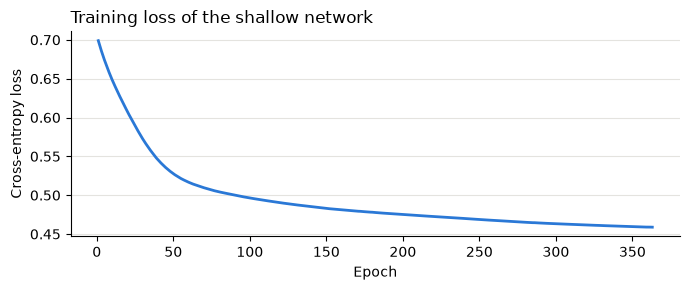

In [12]:
NN_SEED = 0


def shallow_network(seed=NN_SEED, hidden_units=3):
    """Return an untrained network with one hidden layer of ReLU neurons (3 by default), trained with Adam."""
    return MLPClassifier(hidden_layer_sizes=(hidden_units,), activation="relu", solver="adam", max_iter=2000,
                         random_state=seed)


network = shallow_network().fit(X_train, y_train)
assert network.out_activation_ == "logistic", "The output layer isn't a sigmoid"

print(f"Stopped after {network.n_iter_} epochs, final training loss {network.loss_:.4f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(network.loss_curve_) + 1), network.loss_curve_, color=LINE_COLOR, linewidth=2)
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.yaxis.grid(True, color=GRID_COLOR)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Training loss of the shallow network", loc="left")
fig.tight_layout()
plt.show()

## 13. Evaluate the network

AUC is computed on real rows only: the real train rows (synthetic rows excluded), all test rows, and the complete test rows, which
match the manual's evaluation best. A network this small depends on its random starting weights, so the second table retrains it
with 10 different seeds to show how much the scores vary.

In [13]:
def auc_scores(model):
    """Return the AUC on real train rows, all test rows and complete test rows."""
    train_scores = model.predict_proba(X_train[is_real])[:, 1]
    test_scores = model.predict_proba(X_test)[:, 1]
    return {
        "train (real rows)": roc_auc_score(y_train[is_real], train_scores),
        "test (all rows)": roc_auc_score(y_test, test_scores),
        "test (complete rows)": roc_auc_score(y_test[test_is_complete], test_scores[test_is_complete.to_numpy()]),
    }


display(pd.DataFrame(auc_scores(network), index=[f"Seed {NN_SEED}"]).round(3))

seed_scores = pd.DataFrame([auc_scores(shallow_network(seed).fit(X_train, y_train)) for seed in range(10)])
seed_scores.agg(["mean", "std", "min", "max"]).round(3)

,train (real rows),test (all rows),test (complete rows)
Seed 0,0.832,0.832,0.816


,train (real rows),test (all rows),test (complete rows)
mean,0.830,0.837,0.815
std,0.005,0.010,0.015
min,0.822,0.823,0.791
max,0.836,0.853,0.849


## 14. Baseline: HAB rate per season and cluster

The baseline predicts, for each row, the share of train rows with `HAB = 1` that have the same `Season` and `spatial_cluster`.
It is fitted on real train rows only, because synthetic SMOTE rows would distort the rates. A combination with no train rows gets
the overall train rate.

In [14]:
def fit_rate_baseline(data):
    """Return the HAB rate of each (Season, spatial_cluster) pair and the overall HAB rate."""
    return {"rates": data.groupby(["Season", "spatial_cluster"])[TARGET].mean(), "overall": data[TARGET].mean()}


def predict_rate_baseline(baseline, data):
    """Return the HAB rate of each row's pair, or the overall rate for pairs unseen during fitting."""
    pairs = pd.MultiIndex.from_frame(data[["Season", "spatial_cluster"]])
    return baseline["rates"].reindex(pairs).fillna(baseline["overall"]).to_numpy()


baseline = fit_rate_baseline(train)
baseline_train_scores = predict_rate_baseline(baseline, train)
baseline_test_scores = predict_rate_baseline(baseline, test)
unseen = ~pd.MultiIndex.from_frame(test[["Season", "spatial_cluster"]]).isin(baseline["rates"].index)
print(f"Season-cluster pairs in train: {len(baseline['rates'])}, test rows with an unseen pair: {unseen.sum()}")

network_test_mean = seed_scores.mean()
pd.DataFrame({
    "Baseline": {
        "train (real rows)": roc_auc_score(train[TARGET], baseline_train_scores),
        "test (all rows)": roc_auc_score(y_test, baseline_test_scores),
        "test (complete rows)": roc_auc_score(y_test[test_is_complete], baseline_test_scores[test_is_complete.to_numpy()]),
    },
    "Shallow network (mean of 10 seeds)": network_test_mean,
}).T.round(3)

Season-cluster pairs in train: 18, test rows with an unseen pair: 0


,train (real rows),test (all rows),test (complete rows)
Baseline,0.793,0.825,0.776
Shallow network (mean of 10 seeds),0.830,0.837,0.815


## 15. Chronological 5-fold cross-validation

The train set is cut into 5 consecutive time blocks of about 170 rows, and the cuts fall between dates so a date never appears in
two blocks. Each block is the validation fold once, and the model is fitted on the other 4. Rows are never shuffled.

This differs from forward-only validation, where each fold trains only on earlier blocks. Here, earlier folds also train on later
years. Forward-only validation doesn't work with this data, because one of its validation blocks would be February to November
2017, which has no HAB events, so its AUC would be undefined.

Everything learned from data is refitted inside each fold, on the 4 training blocks only: the imputation medians, the scaling
means and standard deviations, SMOTE, the baseline rates and the network. The network is trained with 5 seeds per fold, and its
fold score is the mean over those seeds. AUC is reported on all validation rows and on complete validation rows.

In [15]:
CV_FOLDS = 5
CV_SEEDS = range(5)


def fit_preprocessing(data):
    """Return the imputation medians and the scaling means and standard deviations learned from the data."""
    medians = data[IMPUTE_COLUMNS].median()
    logged = log_chl(data.fillna(medians))
    return medians, logged[SCALE_COLUMNS].mean(), logged[SCALE_COLUMNS].std(ddof=0)


def apply_preprocessing(data, medians, means, stds):
    """Impute, log-transform CHL and z-score the data with previously learned values."""
    prepared = log_chl(data.fillna(medians))
    prepared[SCALE_COLUMNS] = (prepared[SCALE_COLUMNS] - means) / stds
    return prepared


assert apply_preprocessing(train, *fit_preprocessing(train)).equals(train_scaled), "The fold preprocessing doesn't match sections 3-6"

cut_dates = pd.to_datetime([train["Date"].iloc[int(len(train) * i / CV_FOLDS)] for i in range(1, CV_FOLDS)])
fold_of_row = np.searchsorted(cut_dates.to_numpy(), train["Date"].to_numpy(), side="right")

pd.DataFrame([{
    "fold": fold + 1,
    "first date": f"{train['Date'][fold_of_row == fold].min():%Y-%m-%d}",
    "last date": f"{train['Date'][fold_of_row == fold].max():%Y-%m-%d}",
    "rows": (fold_of_row == fold).sum(),
    "positives": train[TARGET][fold_of_row == fold].sum(),
    "complete rows": train["CHL"][fold_of_row == fold].notna().sum(),
    "complete positives": train[TARGET][(fold_of_row == fold) & train["CHL"].notna().to_numpy()].sum(),
} for fold in range(CV_FOLDS)]).set_index("fold")

,first date,last date,rows,positives,complete rows,complete positives
fold,,,,,,
1,2013-02-19,2014-09-09,170,10,80,8
2,2014-09-16,2016-07-19,170,38,71,17
3,2016-07-20,2017-07-26,170,8,102,7
4,2017-07-31,2018-08-20,170,19,100,10
5,2018-08-21,2019-08-19,170,23,99,13


In [16]:
def fold_auc(y_true, score_runs, mask):
    """Return the mean AUC of several score arrays on the rows selected by the mask."""
    return np.mean([roc_auc_score(y_true[mask], scores[mask]) for scores in score_runs])


cv_rows = []
for fold in range(CV_FOLDS):
    fit_part, val_part = train[fold_of_row != fold], train[fold_of_row == fold]
    learned = fit_preprocessing(fit_part)
    fit_smote = smote(apply_preprocessing(fit_part, *learned))
    X_val = feature_matrix(apply_preprocessing(val_part, *learned))
    y_val = val_part[TARGET].to_numpy()
    all_rows = np.ones(len(val_part), dtype=bool)
    complete_rows = val_part["CHL"].notna().to_numpy()

    model_scores = {
        "Baseline": [predict_rate_baseline(fit_rate_baseline(fit_part), val_part)],
        "Shallow network": [
            shallow_network(seed).fit(feature_matrix(fit_smote), fit_smote[TARGET]).predict_proba(X_val)[:, 1]
            for seed in CV_SEEDS
        ],
    }
    for model, score_runs in model_scores.items():
        cv_rows.append({
            "fold": fold + 1,
            "model": model,
            "AUC (all rows)": fold_auc(y_val, score_runs, all_rows),
            "AUC (complete rows)": fold_auc(y_val, score_runs, complete_rows),
        })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.pivot(index="fold", columns="model").round(3))
cv_results.groupby("model")[["AUC (all rows)", "AUC (complete rows)"]].agg(["mean", "std"]).round(3)

AUC (all rows)                 AUC (complete rows)                
model       Baseline Shallow network            Baseline Shallow network
fold                                                                    
1              0.552           0.652               0.530           0.664
2              0.762           0.784               0.767           0.812
3              0.853           0.815               0.840           0.812
4              0.798           0.794               0.832           0.831
5              0.831           0.826               0.826           0.814

AUC (all rows)        AUC (complete rows)       
                          mean    std                mean    std
model                                                           
Baseline                 0.759  0.121               0.759  0.132
Shallow network          0.774  0.070               0.787  0.069

## 16. Model comparison so far

**The shallow network beats the baseline only slightly.**
- **Cross-validation:** the network's mean AUC is 0.774 on all validation rows and 0.787 on complete rows, against 0.759 for the
  baseline on both.
- **Per fold:** the network is clearly better in folds 1 and 2 (for example, 0.652 against 0.552 in fold 1), but in folds 3-5 the
  two are within 0.04 of each other, and the baseline is ahead in fold 3.
- **Test set:** the network scores 0.837 on all rows and 0.815 on complete rows, against 0.825 and 0.776 for the baseline.

**Season and spatial cluster alone explain most of what the network finds.** A model only counts as an improvement if it beats
0.759 in cross-validation by more than the fold-to-fold noise.

**The fold scores vary a lot.** The baseline's standard deviation across folds is 0.12, and the network's is 0.07. Fold 1
(2013-2014) is the hardest for both, likely because it is predicted from later years. Validation folds have only 7-17 complete
positives, so a difference of a few hundredths between models is within noise.

**For model selection:** compare models by their mean cross-validation AUC, using the same folds, and keep the test set for a
final check of the chosen model.


## 17. Hidden layer size

The model's output is the probability of `HAB = 1`, which is what `predict_proba` already returns, so every score in this notebook
is computed on probabilities and no class decision is made.

This section tries hidden layers of 5 to 15 neurons, where 15 is the number of input features (the first line below checks this).
Each size is scored with the same chronological 5 folds and 5 seeds per fold as section 15, so the results can be compared
with the 3-neuron network and the baseline. Everything else about the network stays the same.

The best size is the one with the highest mean AUC on complete validation rows, because the manual's test set has only complete
samples.

In [17]:
HIDDEN_SIZES = range(5, 16)

assert X_train.shape[1] == 15, "The feature matrix doesn't have 15 columns"
print(f"Input features: {X_train.shape[1]}")

fold_data = []
for fold in range(CV_FOLDS):
    fit_part, val_part = train[fold_of_row != fold], train[fold_of_row == fold]
    learned = fit_preprocessing(fit_part)
    fit_smote = smote(apply_preprocessing(fit_part, *learned))
    fold_data.append({
        "X_fit": feature_matrix(fit_smote),
        "y_fit": fit_smote[TARGET],
        "X_val": feature_matrix(apply_preprocessing(val_part, *learned)),
        "y_val": val_part[TARGET].to_numpy(),
        "complete": val_part["CHL"].notna().to_numpy(),
    })

size_rows = []
for units in HIDDEN_SIZES:
    for fold, data in enumerate(fold_data):
        score_runs = [
            shallow_network(seed, units).fit(data["X_fit"], data["y_fit"]).predict_proba(data["X_val"])[:, 1]
            for seed in CV_SEEDS
        ]
        size_rows.append({
            "hidden units": units,
            "fold": fold + 1,
            "AUC (all rows)": fold_auc(data["y_val"], score_runs, np.ones(len(data["y_val"]), dtype=bool)),
            "AUC (complete rows)": fold_auc(data["y_val"], score_runs, data["complete"]),
        })

size_results = pd.DataFrame(size_rows)
size_summary = size_results.groupby("hidden units")[["AUC (all rows)", "AUC (complete rows)"]].agg(["mean", "std"])
best_units = int(size_summary[("AUC (complete rows)", "mean")].idxmax())

reference = cv_results.groupby("model")[["AUC (all rows)", "AUC (complete rows)"]].mean().round(3)
print(f"Best hidden layer size: {best_units} neurons")
print(f"For reference, 3 neurons: {reference.loc['Shallow network'].to_dict()}")
print(f"For reference, baseline: {reference.loc['Baseline'].to_dict()}")
size_summary.round(3)

Input features: 15
Best hidden layer size: 8 neurons
For reference, 3 neurons: {'AUC (all rows)': 0.774, 'AUC (complete rows)': 0.787}
For reference, baseline: {'AUC (all rows)': 0.759, 'AUC (complete rows)': 0.759}


AUC (all rows)        AUC (complete rows)       
                       mean    std                mean    std
hidden units                                                 
5                     0.759  0.072               0.775  0.068
6                     0.760  0.056               0.774  0.046
7                     0.769  0.061               0.787  0.058
8                     0.765  0.059               0.790  0.047
9                     0.768  0.042               0.787  0.033
10                    0.750  0.046               0.768  0.037
11                    0.750  0.053               0.768  0.040
12                    0.746  0.055               0.773  0.048
13                    0.741  0.059               0.754  0.049
14                    0.744  0.052               0.756  0.042
15                    0.747  0.046               0.766  0.029

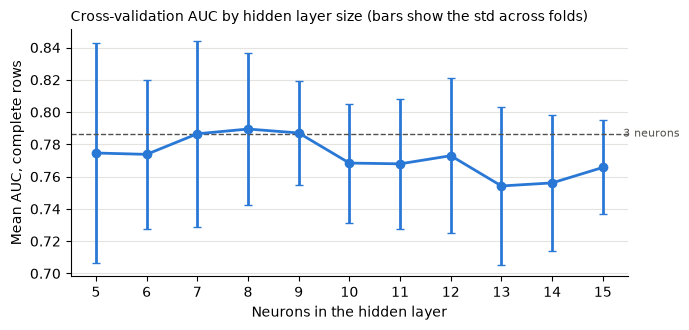

fold,1,2,3,4,5
hidden units,,,,,
5,0.653,0.811,0.791,0.805,0.812
6,0.700,0.808,0.775,0.769,0.818
7,0.685,0.813,0.792,0.817,0.825
8,0.709,0.814,0.793,0.802,0.830
9,0.735,0.800,0.791,0.785,0.824
10,0.736,0.780,0.735,0.767,0.825
11,0.734,0.790,0.728,0.763,0.825
12,0.712,0.816,0.732,0.791,0.814
13,0.698,0.752,0.716,0.789,0.816


In [18]:
complete_mean = size_summary[("AUC (complete rows)", "mean")]
complete_std = size_summary[("AUC (complete rows)", "std")]
three_units = cv_results.loc[cv_results["model"] == "Shallow network", "AUC (complete rows)"].mean()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.errorbar(complete_mean.index, complete_mean, yerr=complete_std, color=LINE_COLOR, linewidth=2, marker="o", capsize=3)
ax.axhline(three_units, color="#52514e", linestyle="--", linewidth=1)
ax.text(15.4, three_units, "3 neurons", color="#52514e", fontsize=8, va="center")
ax.set_xticks(list(HIDDEN_SIZES))
ax.set_xlabel("Neurons in the hidden layer")
ax.set_ylabel("Mean AUC, complete rows")
ax.yaxis.grid(True, color=GRID_COLOR)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Cross-validation AUC by hidden layer size (bars show the std across folds)", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

size_results.pivot(index="hidden units", columns="fold", values="AUC (complete rows)").round(3)

## 18. Test check of the chosen size

The chosen size is retrained on the full SMOTE train set with 10 seeds and scored on the test set, next to the 3-neuron network
from section 13. The size was chosen by cross-validation only, so these test scores are a check and not part of the choice.

In [19]:
best_seed_scores = pd.DataFrame([auc_scores(shallow_network(seed, best_units).fit(X_train, y_train)) for seed in range(10)])

pd.concat({
    "3 neurons": seed_scores.agg(["mean", "std"]),
    f"{best_units} neurons": best_seed_scores.agg(["mean", "std"]),
}).round(3)

train (real rows)  test (all rows)  test (complete rows)
3 neurons mean              0.830            0.837                 0.815
          std               0.005            0.010                 0.015
8 neurons mean              0.887            0.818                 0.804
          std               0.013            0.014                 0.012

## 19. Findings on the hidden layer size

**The best size from 5 to 15 is 8 neurons, but it isn't a real improvement over 3 neurons.**
- **Cross-validation, complete rows:** 8 neurons has the highest mean AUC, 0.790, against 0.787 for 3 neurons. Sizes 7 and 9
  both score 0.787. These differences are far smaller than the standard deviation across folds (0.03 to 0.07).
- **Cross-validation, all rows:** no size from 5 to 15 beats 3 neurons (0.774). The closest are 7 neurons (0.769), 9 (0.768) and
  8 (0.765).
- **Larger layers are worse:** sizes 10 to 15 score 0.754 to 0.773 on complete rows and 0.741 to 0.750 on all rows, which is
  below the baseline's 0.759 on all rows.
- **Test check:** with 8 neurons the test AUC is 0.818 on all rows and 0.804 on complete rows, against 0.837 and 0.815 with
  3 neurons. The AUC on real train rows rises from 0.830 to 0.887, so the larger network fits the train set more closely
  without predicting later data better.

**Fold 1 is the only fold that gains from more neurons** (0.664 with 3 neurons, 0.709 with 8 and up to 0.736 with 10). The
other folds stay level or get worse.


## 20. Hidden layers and L2 regularization

Section 19 showed that a bigger layer fits the train set more closely without predicting later data better, so this section
searches the layer size together with `alpha`, the L2 penalty on the weights (scikit-learn's default is `1e-4`, which is what
every network so far has used).

- **Layers:** 2, 3, 4, 6, 8 and 12 neurons in one hidden layer, plus two layers of 8 and 4 neurons.
- **`alpha`:** `1e-4`, `1e-3`, `1e-2`, `1e-1` and `1`.

Each of the 35 pairs is scored with the same chronological 5 folds (`fold_data` from section 17) and 5 seeds per fold, so the
3-neuron network with `alpha = 1e-4` reproduces section 15.

**How the pair is chosen (one-standard-error rule):** the best pair is the one with the highest mean AUC on complete validation
rows. Every pair whose mean is within one standard error of that best (fold std / sqrt(5)) counts as tied with it, and among the
tied pairs the simplest wins: fewest weights first, then the largest `alpha`. The test set plays no part in the choice.


In [ ]:
HIDDEN_LAYERS = {"2": (2,), "3": (3,), "4": (4,), "6": (6,), "8": (8,), "12": (12,), "8-4": (8, 4)}
ALPHAS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]


def regularized_network(seed=NN_SEED, hidden_layers=(3,), alpha=1e-4):
    """Return an untrained ReLU network with the given hidden layers and L2 penalty, trained with Adam."""
    return MLPClassifier(hidden_layer_sizes=hidden_layers, activation="relu", solver="adam", alpha=alpha,
                         max_iter=2000, random_state=seed)


def weight_count(hidden_layers, n_inputs=X_train.shape[1]):
    """Return the number of weights and biases of a network with these hidden layers and one output neuron."""
    sizes = [n_inputs, *hidden_layers, 1]
    return sum((before + 1) * after for before, after in zip(sizes[:-1], sizes[1:]))


assert regularized_network(0, (3,), 1e-4).get_params() == shallow_network(0, 3).get_params(), \
    "The default pair doesn't match the section 12 network"

grid_rows = []
for layers, hidden_layers in HIDDEN_LAYERS.items():
    for alpha in ALPHAS:
        for fold, data in enumerate(fold_data):
            score_runs = [
                regularized_network(seed, hidden_layers, alpha).fit(data["X_fit"], data["y_fit"]).predict_proba(data["X_val"])[:, 1]
                for seed in CV_SEEDS
            ]
            grid_rows.append({
                "layers": layers,
                "alpha": alpha,
                "fold": fold + 1,
                "AUC (all rows)": fold_auc(data["y_val"], score_runs, np.ones(len(data["y_val"]), dtype=bool)),
                "AUC (complete rows)": fold_auc(data["y_val"], score_runs, data["complete"]),
            })

grid_results = pd.DataFrame(grid_rows)
grid_summary = grid_results.groupby(["layers", "alpha"], sort=False)[["AUC (all rows)", "AUC (complete rows)"]].agg(["mean", "std"])
grid_summary["weights"] = [weight_count(HIDDEN_LAYERS[layers]) for layers, _ in grid_summary.index]

grid_mean = grid_summary[("AUC (complete rows)", "mean")]
best_pair = grid_mean.idxmax()
tie_threshold = grid_mean[best_pair] - grid_summary.loc[best_pair, ("AUC (complete rows)", "std")] / np.sqrt(CV_FOLDS)
tied = grid_summary[grid_mean >= tie_threshold]
tied = tied.loc[sorted(tied.index, key=lambda pair: (tied.loc[pair, "weights"].item(), -pair[1]))]
chosen_layers, chosen_alpha = tied.index[0]

print(f"Best pair: {best_pair[0]} neurons, alpha = {best_pair[1]:g}, mean AUC (complete rows) {grid_mean[best_pair]:.3f}")
print(f"Pairs within one standard error (AUC >= {tie_threshold:.3f}): {len(tied)}")
print(f"Chosen pair: {chosen_layers} neurons, alpha = {chosen_alpha:g}, "
      f"mean AUC (complete rows) {grid_mean[(chosen_layers, chosen_alpha)]:.3f}")
grid_summary.round(3)


In [ ]:
heat = grid_mean.unstack("alpha").loc[list(HIDDEN_LAYERS), ALPHAS]

fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(heat.to_numpy(), cmap="Blues", aspect="auto")
for row, layers in enumerate(heat.index):
    for column, alpha in enumerate(heat.columns):
        value = heat.loc[layers, alpha]
        dark_cell = value > heat.to_numpy().min() + 0.6 * np.ptp(heat.to_numpy())
        ax.text(column, row, f"{value:.3f}", ha="center", va="center", fontsize=8,
                color="white" if dark_cell else "#1f1e1c")
        if (layers, alpha) in [best_pair, (chosen_layers, chosen_alpha)]:
            ax.add_patch(plt.Rectangle((column - 0.5, row - 0.5), 1, 1, fill=False, linewidth=2,
                                       edgecolor="#1f1e1c", linestyle="-" if (layers, alpha) == best_pair else "--"))
ax.set_xticks(range(len(ALPHAS)), [f"{alpha:g}" for alpha in ALPHAS])
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("alpha (L2 penalty)")
ax.set_ylabel("Hidden neurons")
fig.colorbar(image, ax=ax, label="Mean AUC, complete rows")
ax.set_title("Cross-validation AUC by layers and alpha (solid box: best, dashed: chosen)", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

tied.round(3)


## 21. Test check of the chosen pair

The chosen pair is retrained on the full SMOTE train set with 10 seeds and scored on the test set, next to the networks from
sections 13 and 18. As in section 18, the pair was chosen by cross-validation only, so these test scores are a check and not part
of the choice. The gap between the real train rows and the test rows shows how much each network overfits.


In [ ]:
chosen_seed_scores = pd.DataFrame([
    auc_scores(regularized_network(seed, HIDDEN_LAYERS[chosen_layers], chosen_alpha).fit(X_train, y_train))
    for seed in range(10)
])


def with_gap(scores):
    """Return the seed scores plus the gap between the real train rows and the complete test rows."""
    return scores.assign(**{"train - test gap (complete rows)": scores["train (real rows)"] - scores["test (complete rows)"]})


pd.concat({
    "3 neurons, alpha 1e-4": with_gap(seed_scores).agg(["mean", "std"]),
    f"{best_units} neurons, alpha 1e-4": with_gap(best_seed_scores).agg(["mean", "std"]),
    f"{chosen_layers} neurons, alpha {chosen_alpha:g}": with_gap(chosen_seed_scores).agg(["mean", "std"]),
}).round(3)


## 22. Findings on layers and regularization

**Regularization helps the larger networks, but no pair is clearly better than a small network.**
- **Best pair:** 4 neurons with `alpha = 1` has the highest mean AUC on complete validation rows, 0.808, against 0.787 for the
  3-neuron network with the default `alpha = 1e-4`.
- **Almost everything is tied:** 31 of the 35 pairs are within one standard error of the best (AUC >= 0.772). The fold std is
  0.04 to 0.09, mostly because fold 1 is much harder than the others, so differences of 0.01 to 0.02 can't be told apart.
- **Chosen pair:** the simplest tied pair is 2 neurons with `alpha = 1` (35 weights), with a mean AUC of 0.790 on complete rows.
- **`alpha = 1` is the best penalty for every layer size except 2 neurons.** It matters most for the larger networks: 12 neurons
  rise from 0.773 to 0.803 and 8-4 from 0.766 to 0.795. Between `1e-4` and `1e-2` the penalty makes almost no difference.

**Test check:** the chosen pair scores 0.839 on all test rows and 0.808 on complete rows, against 0.837 and 0.815 for 3 neurons
with `alpha = 1e-4`. The gap between real train rows and complete test rows is 0.011 for the chosen pair, 0.015 for 3 neurons and
0.082 for 8 neurons without extra regularization, so the small networks don't overfit.

**What this means:** with these 15 features, the AUC levels off around 0.80 in cross-validation whatever the architecture, as long
as the network is small or strongly regularized. A further gain is more likely to come from the features than from the network.


## 23. Other classifiers

This section compares five other kinds of classifier with the baseline and the networks. Each one is scored with the same
chronological 5 folds as sections 15-20 (`fold_data` from section 17), so every fold has the same imputation, log transform,
scaling and SMOTE, fitted on its 4 training blocks only, and every AUC comes from real validation rows only.

Each classifier is tried with a few settings of the parameter that controls how closely it fits the data:

| Classifier | Settings tried | Fixed settings |
|---|---|---|
| Gaussian Naive Bayes | `var_smoothing`: `1e-9` (default), `1e-6`, `1e-3`, `0.1` | |
| Logistic regression | `C` (inverse L2 penalty): `0.001`, `0.01`, `0.1`, `1`, `10` | `max_iter = 5000` |
| k-nearest neighbours | `n_neighbors`: 5, 15, 31, 51, 101 | uniform weights, Euclidean distance |
| SVM, RBF kernel | `C`: 0.1, 1, 10, with `gamma`: `"scale"`, 0.01, 0.1 | |
| Random forest | `max_depth`: 4, 8, none, with `min_samples_leaf`: 1, 10, 30 | 300 trees |

- **Random forest** depends on its seed, so like the networks it is trained with 5 seeds per fold and its fold score is the mean.
  The other four are deterministic and are fitted once per fold.
- **SVM** is scored with its decision value instead of a probability. AUC only depends on how the rows are ranked, so this gives
  the same AUC as a probability would, without the extra internal cross-validation that `probability=True` runs.
- **Naive Bayes** treats the one-hot `Season` and cluster columns as if they were Gaussian, which is a rough fit for 0/1 columns.
- **kNN** measures distances in the SMOTE train fold, where 87% of the positives are synthetic, so small `n_neighbors` mostly
  finds synthetic rows.

The best setting of each classifier is the one with the highest mean AUC on complete validation rows, as in section 17.
Picking the best of several settings makes its CV score slightly optimistic, more so for the classifiers with more settings
(9 for SVM and random forest, 4 or 5 for the others).

In [ ]:
from itertools import product

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

STOCHASTIC = {RandomForestClassifier}
FIXED_PARAMS = {
    LogisticRegression: {"max_iter": 5000},
    RandomForestClassifier: {"n_estimators": 300, "n_jobs": -1},
}
CANDIDATES = (
    [("Naive Bayes", GaussianNB, {"var_smoothing": value}) for value in [1e-9, 1e-6, 1e-3, 1e-1]]
    + [("Logistic regression", LogisticRegression, {"C": c}) for c in [1e-3, 1e-2, 1e-1, 1, 10]]
    + [("kNN", KNeighborsClassifier, {"n_neighbors": k}) for k in [5, 15, 31, 51, 101]]
    + [("SVM (RBF)", SVC, {"C": c, "gamma": gamma}) for c, gamma in product([0.1, 1, 10], ["scale", 0.01, 0.1])]
    + [("Random forest", RandomForestClassifier, {"max_depth": depth, "min_samples_leaf": leaf})
       for depth, leaf in product([4, 8, None], [1, 10, 30])]
)


def make_model(estimator, params, seed=0):
    """Return an untrained estimator with its fixed settings, the given settings and, if it is random, the seed."""
    seed_param = {"random_state": seed} if estimator in STOCHASTIC else {}
    return estimator(**FIXED_PARAMS.get(estimator, {}), **params, **seed_param)


def positive_scores(model, X):
    """Return a score per row that ranks how likely HAB = 1 is: the probability, or the SVM's decision value."""
    if isinstance(model, SVC):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def settings_label(params):
    """Return the settings as a short 'name=value' string."""
    return ", ".join(f"{name}={value:g}" if isinstance(value, float) else f"{name}={value}" for name, value in params.items())


candidate_rows = []
for family, estimator, params in CANDIDATES:
    seeds = CV_SEEDS if estimator in STOCHASTIC else [0]
    for fold, data in enumerate(fold_data):
        score_runs = [
            positive_scores(make_model(estimator, params, seed).fit(data["X_fit"], data["y_fit"]), data["X_val"])
            for seed in seeds
        ]
        candidate_rows.append({
            "model": family,
            "settings": settings_label(params),
            "fold": fold + 1,
            "AUC (all rows)": fold_auc(data["y_val"], score_runs, np.ones(len(data["y_val"]), dtype=bool)),
            "AUC (complete rows)": fold_auc(data["y_val"], score_runs, data["complete"]),
        })

candidate_results = pd.DataFrame(candidate_rows)
candidate_summary = candidate_results.groupby(["model", "settings"], sort=False)[
    ["AUC (all rows)", "AUC (complete rows)"]].agg(["mean", "std"])
candidate_summary.round(3)

### Best setting of each classifier

The chart and the first table compare the best setting of each classifier with the baseline and the two networks from sections
15 and 20, all on the same folds. The dashed line is the baseline. The last column counts the folds, out of 5, where the model's
AUC on complete rows is above the baseline's. The second table gives each model's AUC on complete rows in every fold.

In [ ]:
best_settings = candidate_summary[("AUC (complete rows)", "mean")].groupby(level="model", sort=False).idxmax()
chosen_network = f"Network, {chosen_layers} neurons, alpha {chosen_alpha:g}"


def fold_scores(results, label):
    """Return the per-fold AUC columns of some CV results, labelled with the model name."""
    return results[["fold", "AUC (all rows)", "AUC (complete rows)"]].assign(model=label)


comparison_folds = pd.concat([
    fold_scores(cv_results[cv_results["model"] == "Baseline"], "Baseline"),
    fold_scores(cv_results[cv_results["model"] == "Shallow network"], "Network, 3 neurons, alpha 1e-4"),
    fold_scores(grid_results[(grid_results["layers"] == chosen_layers) & (grid_results["alpha"] == chosen_alpha)],
                chosen_network),
    *[fold_scores(candidate_results[(candidate_results["model"] == model) & (candidate_results["settings"] == settings)],
                  f"{model} ({settings})") for model, settings in best_settings],
], ignore_index=True)

complete_by_fold = comparison_folds.pivot(index="fold", columns="model", values="AUC (complete rows)")
comparison = comparison_folds.groupby("model")[["AUC (all rows)", "AUC (complete rows)"]].agg(["mean", "std"])
comparison["folds above baseline (complete rows)"] = complete_by_fold.gt(complete_by_fold["Baseline"], axis=0).sum()
comparison = comparison.sort_values(("AUC (complete rows)", "mean"), ascending=False)

order = comparison.index[::-1]
baseline_mean = comparison.loc["Baseline", ("AUC (complete rows)", "mean")]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(order, comparison.loc[order, ("AUC (complete rows)", "mean")],
        xerr=comparison.loc[order, ("AUC (complete rows)", "std")], color=LINE_COLOR, capsize=3)
ax.axvline(baseline_mean, color="#52514e", linestyle="--", linewidth=1)
ax.set_xlim(0.5, 0.95)
ax.set_xlabel("Mean AUC, complete rows (dashed line: baseline)")
ax.xaxis.grid(True, color=GRID_COLOR)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Cross-validation AUC of each classifier's best setting (bars show the std across folds)",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout()
plt.show()

display(comparison.round(3))
complete_by_fold[comparison.index].round(3)

## 24. Test check of the classifiers

The best setting of each classifier is retrained on the full SMOTE train set and scored on the test set, next to the baseline
and the networks from sections 13 and 21. The random forest is trained with 10 seeds and its scores are the mean, like the
networks. The settings were chosen by cross-validation only, so these test scores are a check and not part of the choice.
The rows are in the same order as the cross-validation table.

In [ ]:
def set_scores(model):
    """Return the AUC on real train rows, all test rows and complete test rows, for any classifier."""
    train_scores = positive_scores(model, X_train[is_real])
    test_scores = positive_scores(model, X_test)
    return {
        "train (real rows)": roc_auc_score(y_train[is_real], train_scores),
        "test (all rows)": roc_auc_score(y_test, test_scores),
        "test (complete rows)": roc_auc_score(y_test[test_is_complete], test_scores[test_is_complete.to_numpy()]),
    }


test_rows = {
    "Baseline": {
        "train (real rows)": roc_auc_score(train[TARGET], baseline_train_scores),
        "test (all rows)": roc_auc_score(y_test, baseline_test_scores),
        "test (complete rows)": roc_auc_score(y_test[test_is_complete], baseline_test_scores[test_is_complete.to_numpy()]),
    },
    "Network, 3 neurons, alpha 1e-4": seed_scores.mean(),
    chosen_network: chosen_seed_scores.mean(),
}
for family, settings in best_settings:
    estimator, params = next((e, p) for f, e, p in CANDIDATES if f == family and settings_label(p) == settings)
    seeds = range(10) if estimator in STOCHASTIC else [0]
    runs = pd.DataFrame([set_scores(make_model(estimator, params, seed).fit(X_train, y_train)) for seed in seeds])
    test_rows[f"{family} ({settings})"] = runs.mean()

test_comparison = pd.DataFrame(test_rows).T
test_comparison["train - test gap (complete rows)"] = test_comparison["train (real rows)"] - test_comparison["test (complete rows)"]
test_comparison.loc[comparison.index].round(3)

## 25. Findings on the classifiers

**Logistic regression, the RBF SVM, the regularized networks and the random forest are tied at the top.**
- **Cross-validation, complete rows:** logistic regression with `C = 1` scores 0.796, the SVM with `C = 1, gamma = 0.01` 0.795,
  the 2-neuron network with `alpha = 1` 0.790, the random forest with `max_depth = 4, min_samples_leaf = 30` 0.788 and the
  3-neuron network 0.787. These five are within 0.01 of each other, while the fold std is 0.07 to 0.11, so they can't be told apart.
- **Against the baseline (0.759):** logistic regression, the SVM and the random forest beat it in 4 of the 5 folds. All three lose
  to it in fold 5.
- **Naive Bayes and kNN add nothing over the baseline:** their best settings score 0.760 and 0.759 on complete rows.

**How the settings behave:**
- **Logistic regression** barely changes for `C` from 0.1 to 10 (0.794 to 0.796). Only a very strong penalty, `C = 0.001`, hurts it (0.767).
- **SVM** overfits with a large `C` and a wide `gamma`: `C = 10, gamma = "scale"` drops to 0.698. A small `gamma` of 0.01, which
  makes the boundary smoother, is the best `gamma` for `C = 1` and `C = 10`.
- **Random forest** scores 0.780 to 0.788 for every depth and leaf size, so the trees' settings hardly matter. Larger leaves
  (30 rows) help a little on all rows.
- **kNN** improves steadily from 5 neighbours (0.689) to 101 (0.759). With few neighbours it mostly finds synthetic SMOTE rows,
  so it needs a very smooth neighbourhood to work at all.

**Fold 1 (2013-2014) is still the hardest for every model,** at 0.52 to 0.66. The networks do best there (0.654 and 0.664), and
Naive Bayes is lowest (0.521), below even the baseline (0.530).

**Test check:** logistic regression has the highest test AUC, 0.848 on all rows and 0.820 on complete rows, and its real train
AUC (0.818) is about the same as its test AUC, so it doesn't overfit. The random forest has the largest gap between real train
rows and complete test rows (0.031), the SVM and the 2-neuron network are close behind logistic regression, and kNN and Naive
Bayes stay closest to the baseline.

**What this means:** the models that work all level off around 0.79-0.80 in cross-validation, as section 22 found for the
networks, so the limit is in the features rather than in the classifier. Logistic regression with `C = 1` is the simplest of the
tied models (16 weights, no seed dependence) and has the best test check, so it is a good choice for the final model unless new
features change the picture.